In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.gridspec import GridSpec
import matplotlib as mpl

mpl.rcParams["font.family"] = "Times New Roman"
mpl.rcParams["font.serif"] = ["Times New Roman"]

mpl.rcParams["font.size"] = 12
mpl.rcParams["axes.titlesize"] = 16
mpl.rcParams["axes.labelsize"] = 13

mpl.rcParams["xtick.labelsize"] = 11
mpl.rcParams["ytick.labelsize"] = 11
mpl.rcParams["legend.fontsize"] = 11

mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"

import copy

nlat = 180
nlon = 360

x = np.arange(nlon)
y = np.arange(nlat)

X, Y = np.meshgrid(x,y)

# from the empirical fit our common constats are:

A = 14.38
B = 2.97
C = 0.55

dt = 0.25
steps = 120 # total 1 month every 4 timesteps is a day

decay = 8
threshold = 50

# bipole fn from prev notebooks.

def bipole_gen(lon, lat, B0, sigma, separation, tilt):
    theta = np.radians(tilt)

    dx = (separation/2)*np.cos(theta)
    dy = (separation/2)*np.sin(theta)

    x1 = lon - dx
    x2 = lon + dx
    y1 = lat - dy
    y2 = lat + dy 

    positive = B0 * np.exp(-((X - x1)**2 + (Y - y1)**2) / (2 * sigma**2))
    negative = B0 * np.exp(-((X - x2)**2 + (Y - y2)**2) / (2 * sigma**2))
    return positive - negative

def active_region_gen(N):

    active_region = []

    for i in range(N):

        # Joy's Law latitude
        solar_lat = np.random.uniform(-35, 35)

        if solar_lat >= 0:
            lat = np.random.uniform(90, 170)
        else:
            lat = np.random.uniform(10, 90)

        lon = np.random.uniform(0, 360)

        B0 = np.random.uniform(600, 1200)

        sigma = np.random.uniform(5, 10)

        separation = np.random.uniform(10, 18)

        tilt = 0.5 * np.abs(solar_lat) + np.random.normal(0, 5)

        active_region.append({
            "lon": lon,
            "lat": lat,
            "solar_lat": solar_lat,
            "B0": B0,
            "sigma": sigma,
            "separation": separation,
            "tilt": tilt,
            "age": 0
        })

    return active_region

def differential_rotation(latitude):


    latitude = np.radians(latitude)

    omega =(A - B*np.sin(latitude)**2
              - C*np.sin(latitude)**4)

    return omega 

def position_amend(active_region):
        for region in active_region:
            omega = differential_rotation( region["solar_lat"] )

        region["lon"] += omega*dt
        region["lon"] %= 360

def age_change(active_region):

    for region in active_region:
        region["age"] +=dt

    


def mag_decay(active_region):
    for region in active_region:
        region["B0"] -= decay*dt 

        region["B0"] = max(region["B0"],0)

def defunct_region(active_region):
    return [ region 
            for region in active_region
            
            if region["B0"] >= threshold
            
 ]

def reconstruct_magnetogram(active_region):

    G = np.zeros((nlat,nlon))

    for region in active_region:

        G += bipole_gen(
            region["lon"],
            region["lat"],
            region["B0"],
            region["sigma"],
            region["separation"],
            region["tilt"], )

    return G




As mention in the notes our emperical fit for the decrease in angular momentum comes out to be

$$w = A - Bsin^2(lat) - Csin^4(lat)$$

our common constants for A, B, C = 14.38, 2, 1 refer notes for derivation

Also since our simulation is not synoidal rotation but is a sidereal rotation(inertial and with respect to the distant stars) our equator rotation cycle is 25 days.
In this my main objective is to observe differential rotation and it's effects. I will be introducing a new parameter, angular velocity of the active region.
as the fit suggests, we can now store data with accord to the latitude and make changes appropriately with the longitude.

Therfore during each timestep, the sim computes omega, followed by the changes in the longitude.

Therefore I need to introduce a new function which does all of this at once by linearly computing it smoothly, i.e; differential_rotation()

I feel, it is good plot a omega(lat) vs lat , so as to be understand the analytical perspective and devolop a sense to read the plots da!

Also about the function, since it is a function of latitude, it's arg should be a input in so and output in angular velocity.

In [3]:
#THE SIMULATON (AND IT'S PRELUDE)
def plot_magnetogram(G):
    plt.figure(figsize=(16,8))
    plt.imshow(G, cmap="seismic", origin="lower", extent=[0,360,-90,90])
    plt.title("Synthetic Solar Magnetogram", fontsize=22, pad=14)
    plt.xlabel("Longitude (°)")
    plt.ylabel("Latitude (°)")
    plt.colorbar(label="Magnetic Field (G)")
   
    plt.tight_layout()
    plt.show()

N = 69

active_region = active_region_gen(N)

frames = []
times = []
region_history = []
G = reconstruct_magnetogram(active_region)

frames.append(G.copy())
times.append(0.0)

for step in range(steps):

    position_amend(active_region)

    age_change(active_region)

    mag_decay(active_region)

    active_region = defunct_region(active_region)

    G = reconstruct_magnetogram(active_region)

    frames.append(G.copy())
    times.append((step + 1) * dt)
    region_history.append(copy.deepcopy(active_region))

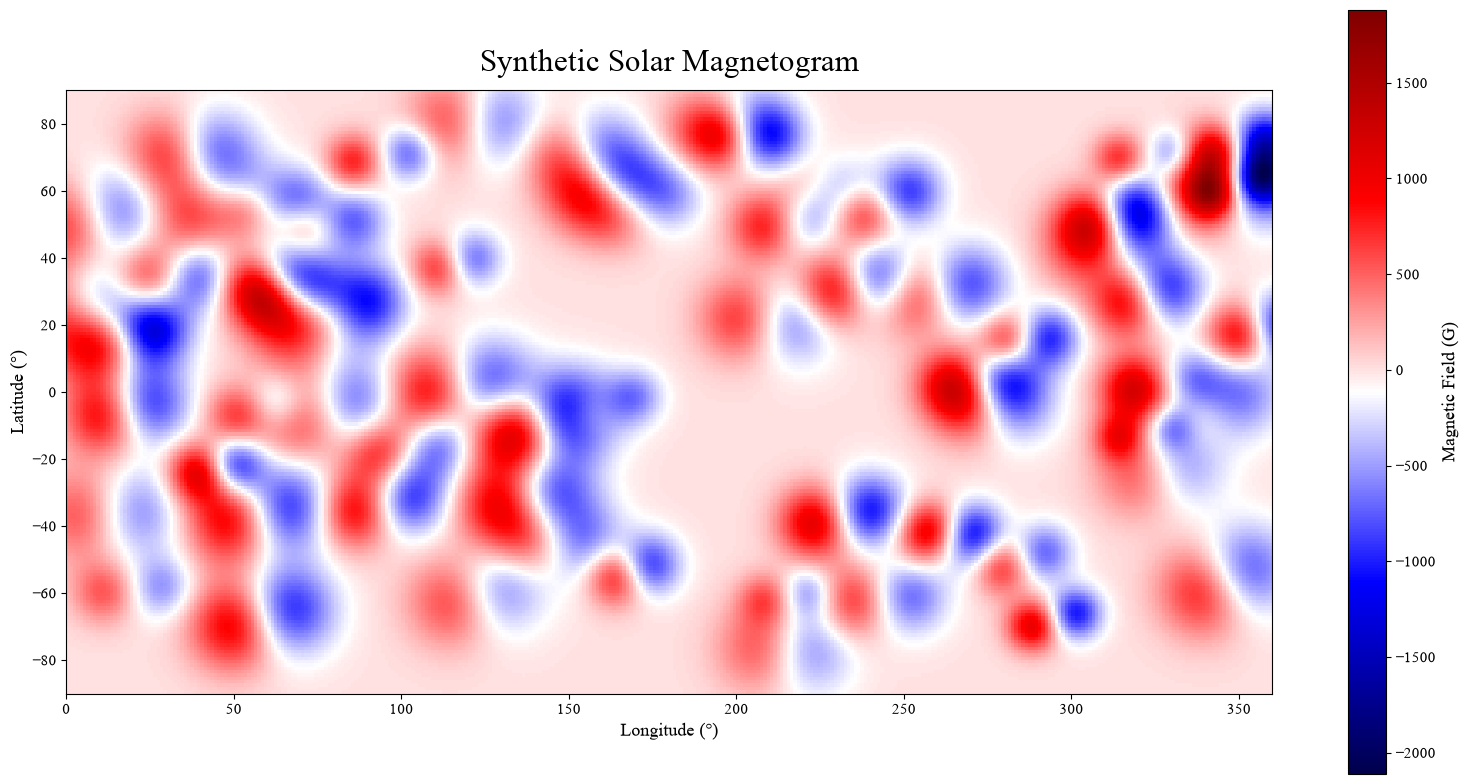

10.0


In [4]:
frame = 40

plot_magnetogram(frames[frame])

print(times[frame])

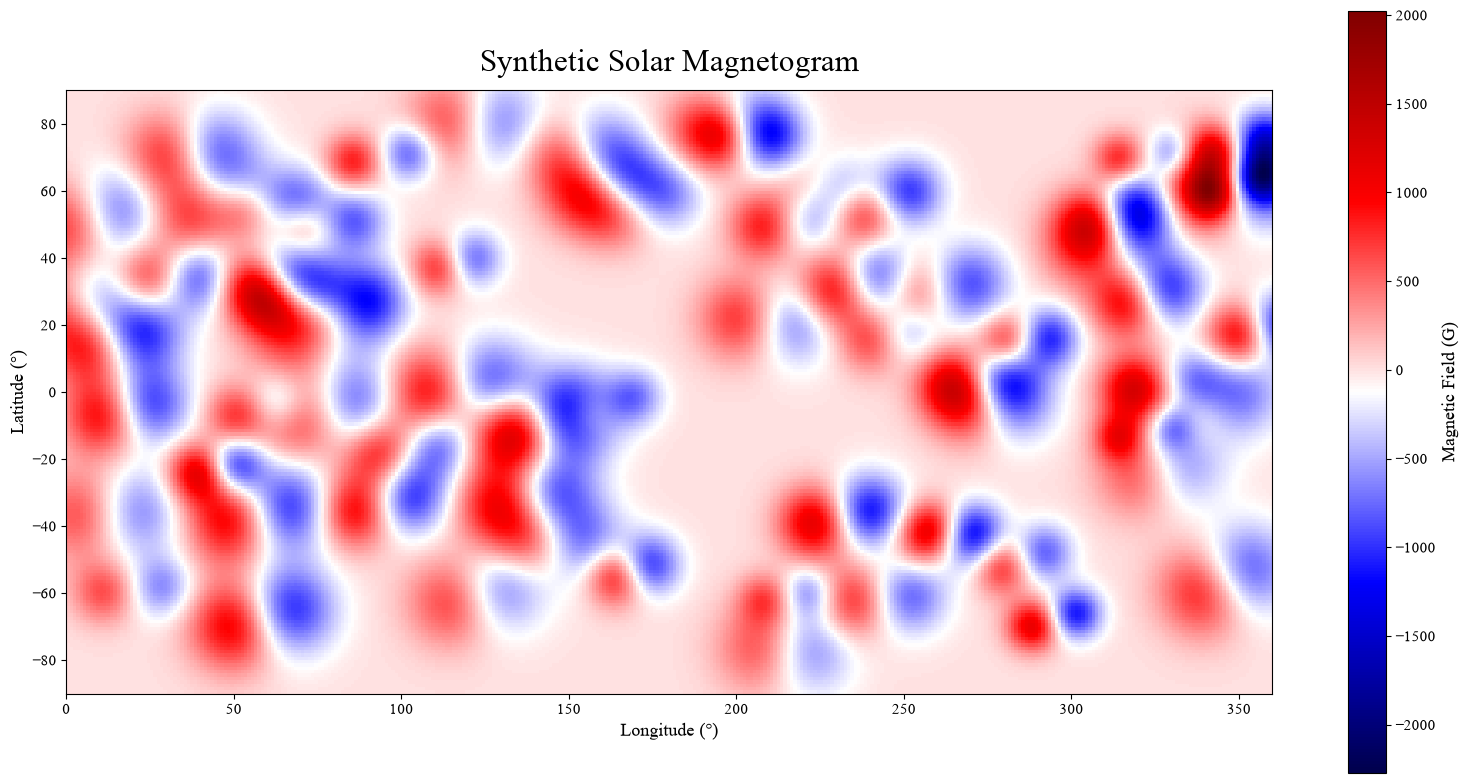

0.0


In [5]:
frame = 0
plot_magnetogram(frames[frame])
print(times[frame])

In [6]:
# v1 where i tried to emulate no graphic changes to the plot refined ig

def plot_magnetogram(G, time=None):
    """
   i'll add this hit later v1 from vs code....
    """

    

    vmax = 1200

    positive_flux = np.sum(G[G > 0])
    negative_flux = np.sum(G[G < 0])

    net_flux = np.sum(G)

    unsigned_flux = np.sum(np.abs(G))

    active_pixels = np.sum(np.abs(G) > 0.10 * vmax)

    flux_balance = (
        100
        * (
            1
            - abs(net_flux)
            / (positive_flux + abs(negative_flux))
        )
        if (positive_flux + abs(negative_flux)) > 0
        else 100 )


    fig = plt.figure(
        figsize=(16,8),
        facecolor="white")

    gs = GridSpec(
        2,
        2,
        figure=fig,
        width_ratios=[40,1.3],
        height_ratios=[18,3],
        wspace=0.08,
        hspace=0.16)

    ax = fig.add_subplot(gs[0,0])

    cax = fig.add_subplot(gs[0,1])

    stat_ax = fig.add_subplot(gs[1,:])


    image = ax.imshow(
        G,
        origin="lower",
        extent=[0,360,-90,90],
        cmap="seismic",
        interpolation="lanczos",
        aspect="auto",
        vmin=-vmax,
        vmax=vmax )

 
    #line contours
 

    contour_levels = [
        -800,
        -400,
        400,
        800]

    ax.contour(
        G,
        levels=contour_levels,
        colors="dimgray",
        linewidths=0.35,
        origin="lower",
        extent=[0,360,-90,90])

   
    #ref lines
    

    ax.axhline(
        0,
        color="black",
        linewidth=0.7,
        alpha=0.35)

    ax.axvline(
        180,
        color="gold",
        linewidth=0.8,
        linestyle="--",
        alpha=0.6 )


    ax.set_xlabel(
        "Carrington Longitude (°)",
        fontsize=14 )

    ax.set_ylabel(
        "Solar Latitude (°)",
        fontsize=14 )

    ax.set_xticks(np.arange(0,361,60))

    ax.set_yticks(np.arange(-90,91,30))

    ax.tick_params(
        labelsize=11 )

    ax.grid(
        linestyle=":",
        linewidth=0.6,
        alpha=0.18,
        color="gray")

    ax.set_facecolor("#f8f8f8")

    for spine in ax.spines.values():
        spine.set_linewidth(0.9)
          
    if time is None:

        ax.set_title(
            "Synthetic Photospheric Magnetogram",
            fontsize=18,
            fontweight="bold",
            pad=14 )

    else:

        carrington_rotation = time / 27.27

        ax.set_title(
            "Synthetic Photospheric Magnetogram\n"
            f"Simulation Day {time:.2f}    |    "
            f"Carrington Rotation {carrington_rotation:.2f}",
            fontsize=18,
            fontweight="bold",
            pad=14 )

   
    cbar = fig.colorbar(
        image,
        cax=cax )

    cbar.set_label(
        "Radial Magnetic Field (G)",
        rotation=270,
        labelpad=20,
        fontsize=12 )

    cbar.ax.tick_params(
        labelsize=10 )

   
    # Stats panel


    stat_ax.axis("off")

    stat_text = (
        f"Positive Flux : {positive_flux:10.2e}      "
        f"Negative Flux : {negative_flux:10.2e}      "
        f"Net Flux : {net_flux:10.2e}\n"
        f"Unsigned Flux : {unsigned_flux:10.2e}      "
        f"Flux Balance : {flux_balance:6.2f}%      "
        f"Active Pixels : {active_pixels:,}"
    )

    stat_ax.text(
        0.01,
        0.5,
        stat_text,
        fontsize=11,
        family="monospace",
        va="center",
        bbox=dict(
            facecolor="whitesmoke",
            edgecolor="gray",
            boxstyle="round,pad=0.45",
            alpha=0.95
        )
    )

    
    plt.show()

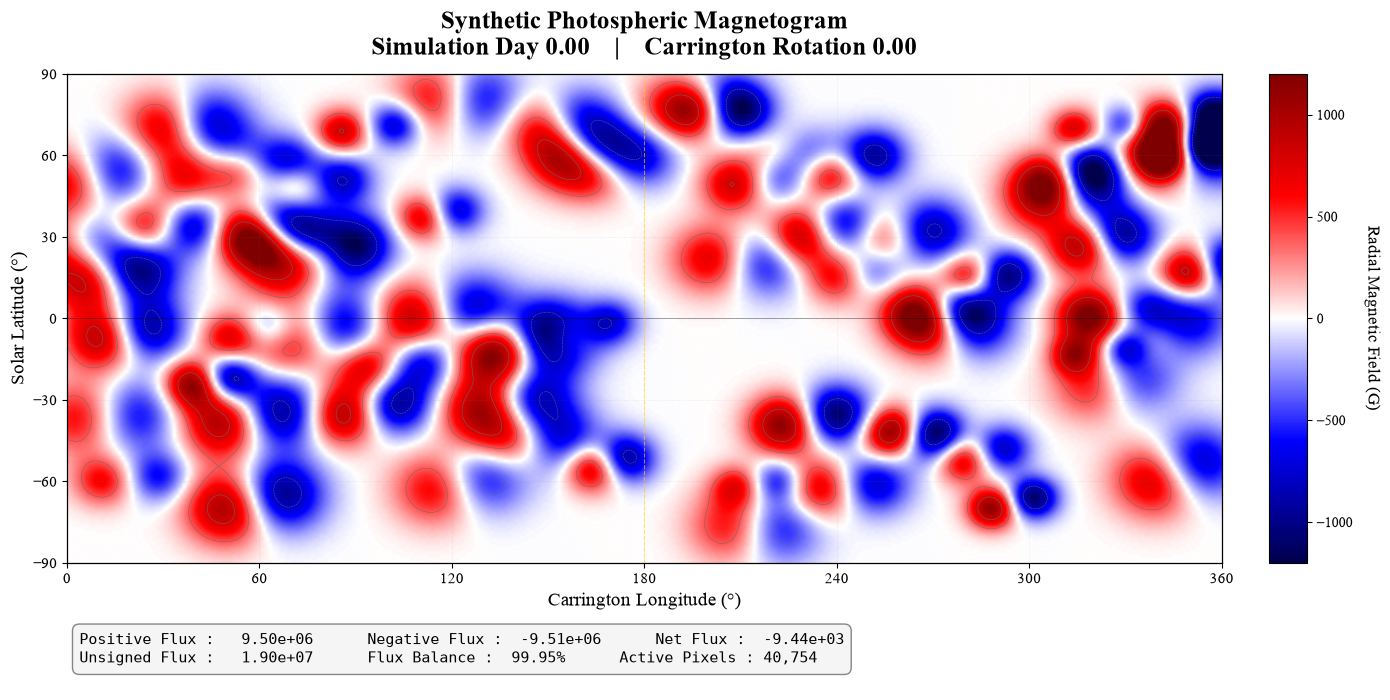

In [7]:
frame = 0

plot_magnetogram(
    frames[frame],
    times[frame]
)


In [8]:
# v2 more polished version where i gave up my sanity

def plot_magnetogram(G, active_region, time):

    """
    lator gator way too many changes to make
    """

  
    positive_flux = np.sum(G[G > 0])
    negative_flux = np.sum(G[G < 0])

    net_flux = positive_flux + negative_flux

    unsigned_flux = np.sum(np.abs(G))

    total_flux = positive_flux + abs(negative_flux)

    if total_flux > 0:

        flux_balance = 100 * (
            1 - abs(net_flux) / total_flux
        )

    else:

        flux_balance = 100.0

   
    # magn field stats


    max_B = np.max(G)
    min_B = np.min(G)

    mean_B = np.mean(np.abs(G))
    rms_B = np.sqrt(np.mean(G**2))

    std_B = np.std(G)

   
    #active reg stats
    
    n_regions = len(active_region)

    if n_regions > 0:

        ages = [spot["age"] for spot in active_region]

        latitudes = [spot["solar_lat"] for spot in active_region]

        strengths = [spot["B0"] for spot in active_region]

        mean_age = np.mean(ages)
        oldest_region = np.max(ages)

        mean_latitude = np.mean(latitudes)

        strongest_region = np.max(strengths)

    else:

        mean_age = 0

        oldest_region = 0

        mean_latitude = 0

        strongest_region = 0

    carrington_rotation = time / 27.27

  

    fig = plt.figure(
        figsize=(20,10),
        facecolor="lightgrey" )

    gs = GridSpec(
        12,
        15,
        figure=fig,
        wspace=0.9,
        hspace=0.7 )

    ax = fig.add_subplot(gs[:, :11])

    ax_stats = fig.add_subplot(gs[:6, 12:15])

    ax_cbar = fig.add_subplot(gs[5:9, 11:])

    ax_hist = fig.add_subplot(gs[9:, 12:15])



    im = ax.imshow(
        G,
        cmap="hot",
        origin="lower",
        extent=[0,360,-90,90],
        interpolation="lanczos",
        aspect="auto",
        vmin=-1200,
        vmax=1200 )



    contour_levels = [

        -1000,
        -800,
        -600,
        -400,

         400,
         600,
         800,
        1000

    ]

    ax.contour(
        G,
        levels=contour_levels,
        colors="dimgray",
        linewidths=0.35,
        origin="lower",
        extent=[0,360,-90,90] )

   
    #reference lines


    ax.axhline(
        0,
        color="black",
        linewidth=0.8,
        linestyle="--",
        alpha=0.30 )

    ax.axvline(
        180,
        color="green",
        linewidth=1.0,
        linestyle="--",
        alpha=0.60 )

    ax.text(
        8,
        84,
        "Positive",
        fontsize=10,
        color="darkred",
        weight="bold" )

    ax.text(
        8,
        -86,
        "Negative",
        fontsize=10,
        color="navy",
        weight="bold" )

   
    ax.set_xlabel(
        "Carrington Longitude (°)",
        fontsize=14,
        weight="bold" )

    ax.set_ylabel(
        "Solar Latitude (°)",
        fontsize=14,
        weight="bold" )

    ax.set_xticks(np.arange(0, 361, 60))
    ax.set_yticks(np.arange(-90, 91, 30))

    ax.tick_params(
        labelsize=11 )

    ax.grid(
        linestyle=":",
        linewidth=0.6,
        alpha=0.18,
        color="gray" )

    ax.set_facecolor("#f8f8f8")

    for spine in ax.spines.values():
        spine.set_linewidth(0.9)

  #title

    ax.set_title(
        "Synthetic Photospheric Magnetogram\n"
        f"Simulation Day {time:.2f}   |   "
        f"Carrington Rotation {carrington_rotation:.2f}   |   "
        f"Active Regions : {n_regions}",
        fontsize=19,
        fontweight="bold",
        pad=16 )

   

    cbar = fig.colorbar(
        im,
        cax=ax_cbar )

    cbar.set_label(
        "Radial Magnetic Field (G)",
        fontsize=10,
        weight="bold" )

    cbar.ax.tick_params(
        labelsize=8 )

  
    #stats panel
  

    stats = (
        f"Positive Flux : {positive_flux:10.2e}\n"
        f"Negative Flux : {negative_flux:10.2e}\n"
        f"Net Flux      : {net_flux:10.2e}\n"
        f"Unsigned Flux : {unsigned_flux:10.2e}\n\n"
        f"Flux Balance  : {flux_balance:6.2f}%\n\n"
        f"Maximum B     : {max_B:7.1f} G\n"
        f"Minimum B     : {min_B:7.1f} G\n"
        f"Mean |B|      : {mean_B:7.1f} G\n"
        f"RMS B         : {rms_B:7.1f} G\n"
        f"Std(B)        : {std_B:7.1f} G\n\n"
        f"Regions       : {n_regions}\n"
        f"Mean Age      : {mean_age:5.1f} d\n"
        f"Oldest Region : {oldest_region:5.1f} d\n"
        f"Mean Latitude : {mean_latitude:5.1f}°\n"
        f"Strongest B₀  : {strongest_region:6.1f} G"
    )

    ax_stats.axis("off")

    ax_stats.text(
        0,
        1,
        stats,
        fontsize=9,
        family="monospace",
        va="top",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="whitesmoke",
            edgecolor="gray",
            alpha=0.95
        )
    )


    field = G[np.abs(G) > 5]

    ax_hist.hist(
        field,
        bins=60,
        density=True,
        edgecolor="black",
        linewidth=0.3
    )

    ax_hist.axvline(
        np.mean(field),
        linestyle="--",
        linewidth=1
    )

    ax_hist.set_xlim(-1200, 1200)

    ax_hist.set_title(
        "Field Distribution",
        fontsize=10,
        weight="bold" )

    ax_hist.set_xlabel(
        "Magnetic Field (G)",
        fontsize=10,
        weight="bold" )
    

    ax_hist.set_ylabel(
        "Probability Density",
        fontsize=10,
        weight="bold" )

    ax_hist.tick_params(
        labelsize=8 )


   

    plt.show()

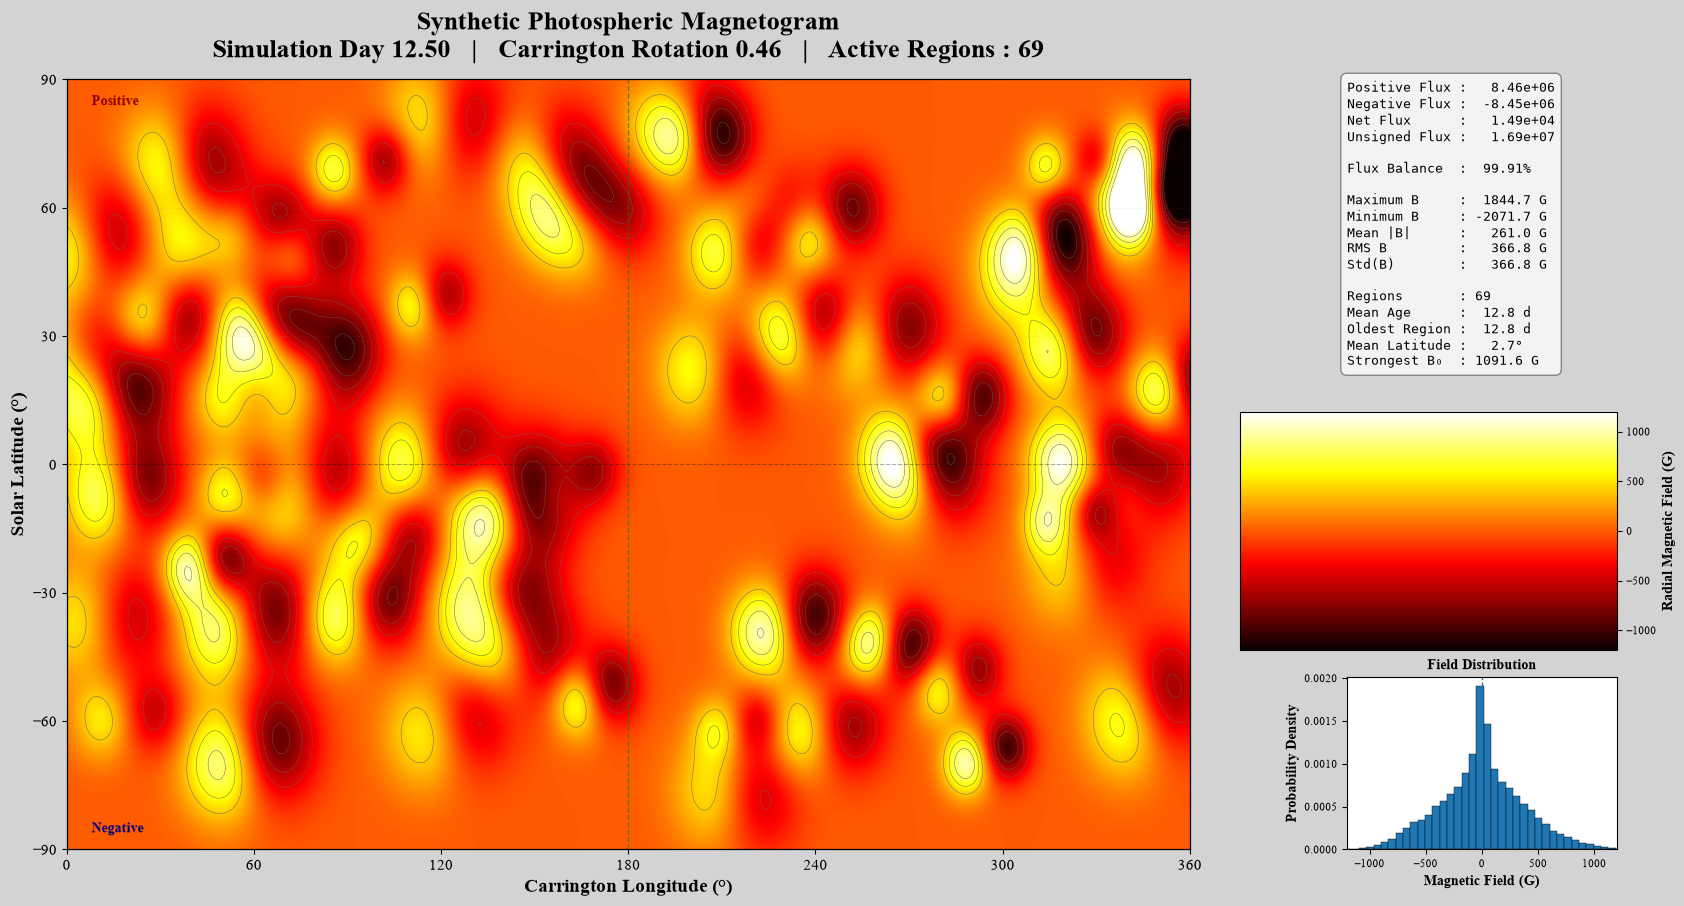

In [9]:
frame = 50

plot_magnetogram(
    frames[frame],
    region_history[frame],
    times[frame]
)

In [10]:
from matplotlib import font_manager

fonts = sorted(set(f.name for f in font_manager.fontManager.ttflist))

print("Times New Roman" in fonts)

True


In [11]:
from matplotlib import font_manager

fonts = sorted(set(f.name for f in font_manager.fontManager.ttflist))

for f in fonts:
    if "Times" in f:
        print(f)

Times New Roman


In [12]:
from matplotlib import font_manager

for f in font_manager.fontManager.ttflist:
    if f.name == "Times New Roman":
        print(f.fname)

/usr/share/fonts/truetype/msttcorefonts/timesbi.ttf
/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf
/usr/share/fonts/truetype/msttcorefonts/timesi.ttf
/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf
/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Italic.ttf
/usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold_Italic.ttf
/usr/share/fonts/truetype/msttcorefonts/times.ttf
/usr/share/fonts/truetype/msttcorefonts/timesbd.ttf


In [13]:
from matplotlib import font_manager

for f in font_manager.fontManager.ttflist:
    if "Times New Roman" in f.name:
        print(f.name, "|", f.weight, "|", f.fname)

Times New Roman | 700 | /usr/share/fonts/truetype/msttcorefonts/timesbi.ttf
Times New Roman | 700 | /usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold.ttf
Times New Roman | 400 | /usr/share/fonts/truetype/msttcorefonts/timesi.ttf
Times New Roman | 400 | /usr/share/fonts/truetype/msttcorefonts/Times_New_Roman.ttf
Times New Roman | 400 | /usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Italic.ttf
Times New Roman | 700 | /usr/share/fonts/truetype/msttcorefonts/Times_New_Roman_Bold_Italic.ttf
Times New Roman | 400 | /usr/share/fonts/truetype/msttcorefonts/times.ttf
Times New Roman | 700 | /usr/share/fonts/truetype/msttcorefonts/timesbd.ttf
